In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    StandardScaler,
    PolynomialFeatures,
)
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)


dataset_path = Path(
    "../data/processed/airfoil_dataset_final.csv"
)

data = pd.read_csv(dataset_path)


features = [
    "max_camber",
    "camber_position",
    "thickness",
    "reynolds",
    "alpha",
]


# Same unseen-airfoil validation set
test_airfoils = [
    "NACA 0012",
    "NACA 2412",
    "NACA 4412",
]


train_data = data[
    ~data["airfoil"].isin(test_airfoils)
].copy()

test_data = data[
    data["airfoil"].isin(test_airfoils)
].copy()


X_train = train_data[features]
X_test = test_data[features]


# Degree-3 selected model
cl_model = Pipeline([
    ("scaler", StandardScaler()),
    (
        "poly",
        PolynomialFeatures(
            degree=3,
            include_bias=False,
        ),
    ),
    ("regression", LinearRegression()),
])


cd_model = Pipeline([
    ("scaler", StandardScaler()),
    (
        "poly",
        PolynomialFeatures(
            degree=3,
            include_bias=False,
        ),
    ),
    ("regression", LinearRegression()),
])


cl_model.fit(
    X_train,
    train_data["CL"],
)

cd_model.fit(
    X_train,
    train_data["CD"],
)


test_data["CL_pred"] = cl_model.predict(
    X_test
)

test_data["CD_pred"] = cd_model.predict(
    X_test
)


test_data["CL_abs_error"] = abs(
    test_data["CL"]
    - test_data["CL_pred"]
)

test_data["CD_abs_error"] = abs(
    test_data["CD"]
    - test_data["CD_pred"]
)


print("Training rows:", len(train_data))
print("Test rows:", len(test_data))

print("\nSelected model: Degree-3 polynomial regression")

Training rows: 1644
Test rows: 281

Selected model: Degree-3 polynomial regression


In [2]:
error_by_alpha = (
    test_data
    .groupby("alpha")
    .agg(
        CL_MAE=(
            "CL_abs_error",
            "mean",
        ),
        CD_MAE=(
            "CD_abs_error",
            "mean",
        ),
    )
    .reset_index()
)

error_by_alpha

,alpha,CL_MAE,CD_MAE
0,-6.0,0.029205,0.005860
1,-5.0,0.026171,0.002942
2,-4.0,0.030942,0.002357
3,-3.0,0.035557,0.001911
4,-2.0,0.032795,0.001900
5,-1.0,0.025150,0.002278
6,0.0,0.024559,0.002313
7,1.0,0.028489,0.002250
8,2.0,0.025616,0.002645
9,3.0,0.022161,0.002644


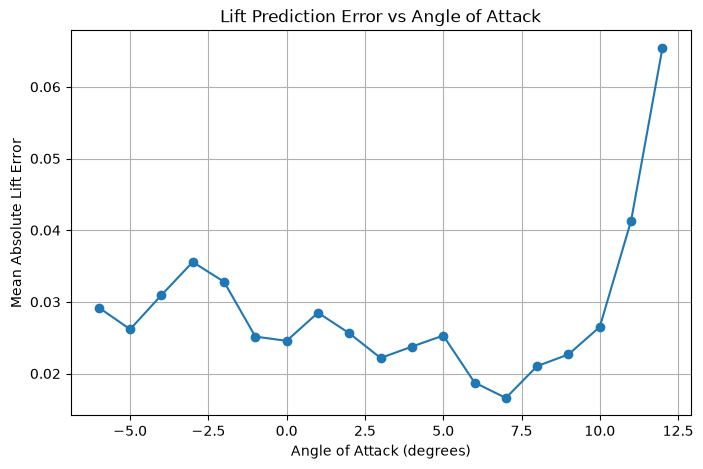

In [3]:
plt.figure(figsize=(8, 5))

plt.plot(
    error_by_alpha["alpha"],
    error_by_alpha["CL_MAE"],
    marker="o",
)

plt.xlabel("Angle of Attack (degrees)")
plt.ylabel("Mean Absolute Lift Error")

plt.title(
    "Lift Prediction Error vs Angle of Attack"
)

plt.grid()

plt.show()

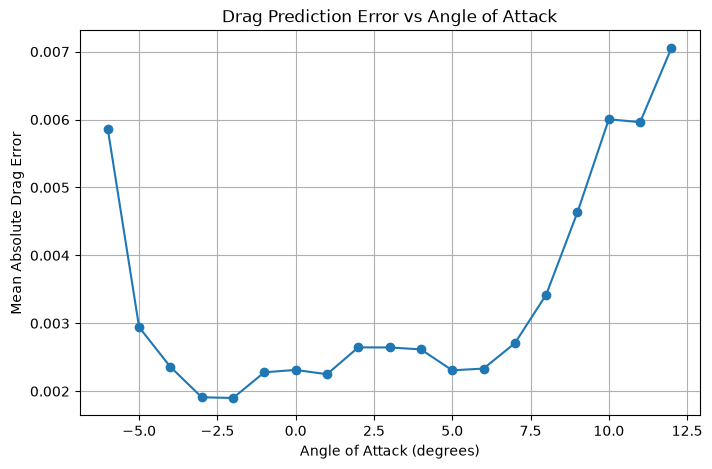

In [4]:
plt.figure(figsize=(8, 5))

plt.plot(
    error_by_alpha["alpha"],
    error_by_alpha["CD_MAE"],
    marker="o",
)

plt.xlabel("Angle of Attack (degrees)")
plt.ylabel("Mean Absolute Drag Error")

plt.title(
    "Drag Prediction Error vs Angle of Attack"
)

plt.grid()

plt.show()

In [5]:
error_by_re = (
    test_data
    .groupby("reynolds")
    .agg(
        CL_MAE=(
            "CL_abs_error",
            "mean",
        ),
        CD_MAE=(
            "CD_abs_error",
            "mean",
        ),
    )
    .reset_index()
)

error_by_re

,reynolds,CL_MAE,CD_MAE
0,100000,0.044816,0.005104
1,200000,0.033518,0.004442
2,300000,0.026146,0.003556
3,400000,0.020726,0.002435
4,500000,0.017081,0.001280


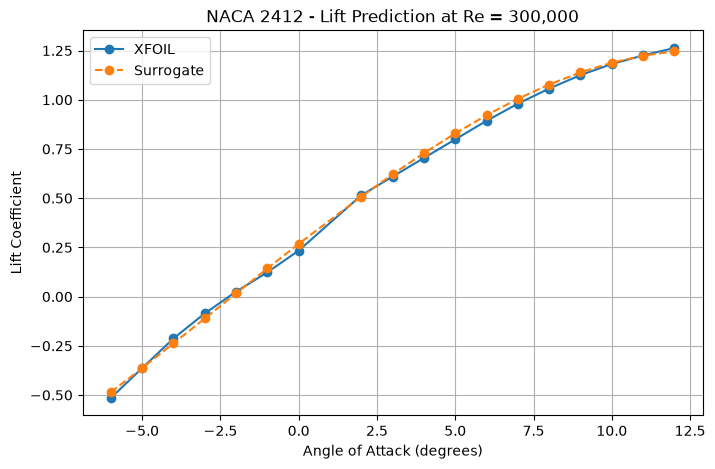

In [6]:
example = test_data[
    (test_data["airfoil"] == "NACA 2412")
    &
    (test_data["reynolds"] == 300000)
].sort_values("alpha")


plt.figure(figsize=(8, 5))

plt.plot(
    example["alpha"],
    example["CL"],
    marker="o",
    label="XFOIL",
)

plt.plot(
    example["alpha"],
    example["CL_pred"],
    marker="o",
    linestyle="--",
    label="Surrogate",
)

plt.xlabel("Angle of Attack (degrees)")
plt.ylabel("Lift Coefficient")

plt.title(
    "NACA 2412 - Lift Prediction at Re = 300,000"
)

plt.legend()
plt.grid()

plt.show()

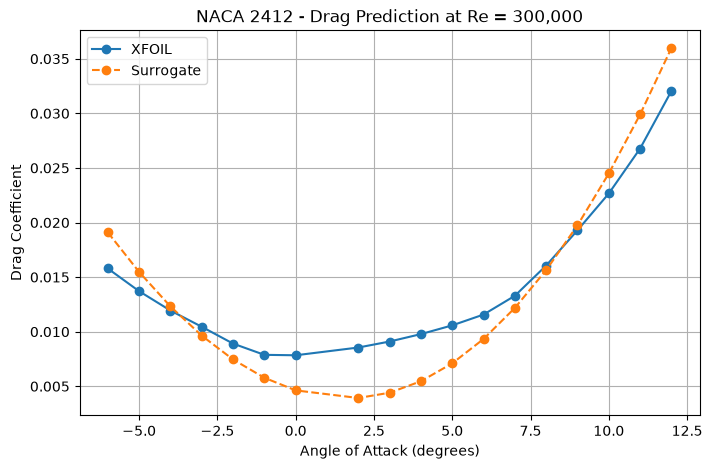

In [7]:
plt.figure(figsize=(8, 5))

plt.plot(
    example["alpha"],
    example["CD"],
    marker="o",
    label="XFOIL",
)

plt.plot(
    example["alpha"],
    example["CD_pred"],
    marker="o",
    linestyle="--",
    label="Surrogate",
)

plt.xlabel("Angle of Attack (degrees)")
plt.ylabel("Drag Coefficient")

plt.title(
    "NACA 2412 - Drag Prediction at Re = 300,000"
)

plt.legend()
plt.grid()

plt.show()

In [8]:
print("WORST LIFT PREDICTIONS")

display(
    test_data[
        [
            "airfoil",
            "reynolds",
            "alpha",
            "CL",
            "CL_pred",
            "CL_abs_error",
        ]
    ]
    .sort_values(
        "CL_abs_error",
        ascending=False,
    )
    .head(10)
)


print("\nWORST DRAG PREDICTIONS")

display(
    test_data[
        [
            "airfoil",
            "reynolds",
            "alpha",
            "CD",
            "CD_pred",
            "CD_abs_error",
        ]
    ]
    .sort_values(
        "CD_abs_error",
        ascending=False,
    )
    .head(10)
)

WORST LIFT PREDICTIONS


,airfoil,reynolds,alpha,CL,CL_pred,CL_abs_error
91,NACA 0012,100000,12.0,0.7976,0.964346,0.166746
78,NACA 0012,100000,-1.0,-0.2578,-0.102048,0.155752
77,NACA 0012,100000,-2.0,-0.3737,-0.232334,0.141366
129,NACA 0012,300000,12.0,1.1397,1.023046,0.116654
110,NACA 0012,200000,12.0,1.0993,0.987597,0.111703
80,NACA 0012,100000,1.0,0.2578,0.149525,0.108275
81,NACA 0012,100000,2.0,0.3736,0.268688,0.104912
109,NACA 0012,200000,11.0,1.0708,0.967313,0.103487
95,NACA 0012,200000,-3.0,-0.4463,-0.348842,0.097458
632,NACA 2412,100000,-3.0,-0.3069,-0.209770,0.097130



WORST DRAG PREDICTIONS


,airfoil,reynolds,alpha,CD,CD_pred,CD_abs_error
1459,NACA 4412,100000,-6.0,0.07963,0.047819,0.031811
110,NACA 0012,200000,12.0,0.04416,0.063025,0.018865
129,NACA 0012,300000,12.0,0.03402,0.052284,0.018264
109,NACA 0012,200000,11.0,0.03626,0.053590,0.017330
128,NACA 0012,300000,11.0,0.02851,0.044311,0.015801
108,NACA 0012,200000,10.0,0.02975,0.045040,0.015290
148,NACA 0012,400000,12.0,0.02939,0.044029,0.014639
127,NACA 0012,300000,10.0,0.02398,0.037101,0.013121
88,NACA 0012,100000,9.0,0.03553,0.048436,0.012906
147,NACA 0012,400000,11.0,0.02480,0.037468,0.012668


In [9]:
alpha_values = np.arange(
    -6,
    13,
    1,
)

alpha_sensitivity = pd.DataFrame({
    "max_camber": 0.02,
    "camber_position": 0.4,
    "thickness": 0.12,
    "reynolds": 300000,
    "alpha": alpha_values,
})

alpha_sensitivity["CL_pred"] = (
    cl_model.predict(
        alpha_sensitivity[features]
    )
)

alpha_sensitivity["CD_pred"] = (
    cd_model.predict(
        alpha_sensitivity[features]
    )
)

alpha_sensitivity

,max_camber,camber_position,thickness,reynolds,alpha,CL_pred,CD_pred
0,0.02,0.4,0.12,300000,-6,-0.485982,0.019099
1,0.02,0.4,0.12,300000,-5,-0.363146,0.015472
2,0.02,0.4,0.12,300000,-4,-0.237779,0.012314
3,0.02,0.4,0.12,300000,-3,-0.110945,0.009637
4,0.02,0.4,0.12,300000,-2,0.016296,0.007455
5,0.02,0.4,0.12,300000,-1,0.142881,0.005780
6,0.02,0.4,0.12,300000,0,0.267749,0.004625
7,0.02,0.4,0.12,300000,1,0.389837,0.004003
8,0.02,0.4,0.12,300000,2,0.508083,0.003927
9,0.02,0.4,0.12,300000,3,0.621425,0.004409


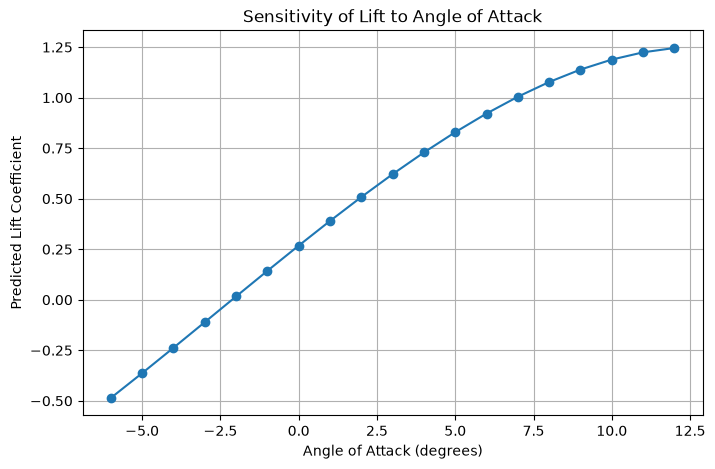

In [10]:
plt.figure(figsize=(8, 5))

plt.plot(
    alpha_sensitivity["alpha"],
    alpha_sensitivity["CL_pred"],
    marker="o",
)

plt.xlabel("Angle of Attack (degrees)")
plt.ylabel("Predicted Lift Coefficient")

plt.title(
    "Sensitivity of Lift to Angle of Attack"
)

plt.grid()
plt.show()

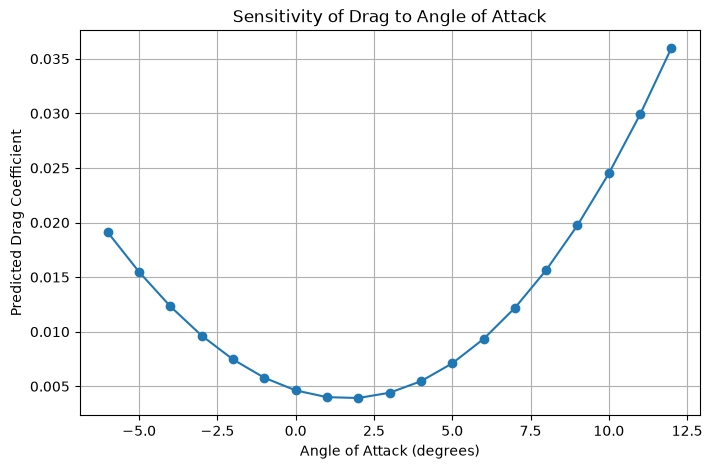

In [11]:
plt.figure(figsize=(8, 5))

plt.plot(
    alpha_sensitivity["alpha"],
    alpha_sensitivity["CD_pred"],
    marker="o",
)

plt.xlabel("Angle of Attack (degrees)")
plt.ylabel("Predicted Drag Coefficient")

plt.title(
    "Sensitivity of Drag to Angle of Attack"
)

plt.grid()
plt.show()

In [12]:
re_values = np.array([
    100000,
    200000,
    300000,
    400000,
    500000,
])

re_sensitivity = pd.DataFrame({
    "max_camber": 0.02,
    "camber_position": 0.4,
    "thickness": 0.12,
    "reynolds": re_values,
    "alpha": 4.0,
})

re_sensitivity["CL_pred"] = (
    cl_model.predict(
        re_sensitivity[features]
    )
)

re_sensitivity["CD_pred"] = (
    cd_model.predict(
        re_sensitivity[features]
    )
)

re_sensitivity

,max_camber,camber_position,thickness,reynolds,alpha,CL_pred,CD_pred
0,0.02,0.4,0.12,100000,4.0,0.710226,0.013115
1,0.02,0.4,0.12,200000,4.0,0.730375,0.007103
2,0.02,0.4,0.12,300000,4.0,0.728801,0.005462
3,0.02,0.4,0.12,400000,4.0,0.716215,0.006176
4,0.02,0.4,0.12,500000,4.0,0.703327,0.007228


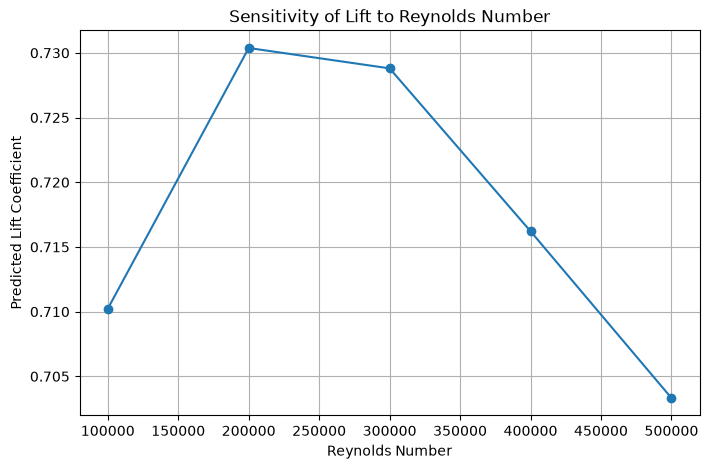

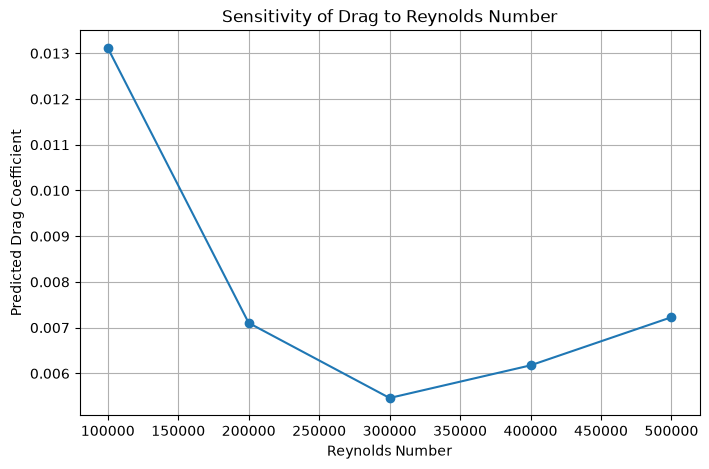

In [14]:
plt.figure(figsize=(8, 5))

plt.plot(
    re_sensitivity["reynolds"],
    re_sensitivity["CL_pred"],
    marker="o",
    label="Lift coefficient",
)

plt.xlabel("Reynolds Number")
plt.ylabel("Predicted Lift Coefficient")

plt.title(
    "Sensitivity of Lift to Reynolds Number"
)

plt.grid()
plt.show() 

plt.figure(figsize=(8, 5))

plt.plot(
    re_sensitivity["reynolds"],
    re_sensitivity["CD_pred"],
    marker="o",
    label="Drag coefficient",
)

plt.xlabel("Reynolds Number")
plt.ylabel("Predicted Drag Coefficient")

plt.title(
    "Sensitivity of Drag to Reynolds Number"
)

plt.grid()
plt.show()

In [15]:
camber_values = np.array([
    0.00,
    0.01,
    0.02,
    0.03,
    0.04,
])

camber_sensitivity = pd.DataFrame({
    "max_camber": camber_values,
    "camber_position": 0.4,
    "thickness": 0.12,
    "reynolds": 300000,
    "alpha": 4.0,
})

camber_sensitivity["CL_pred"] = (
    cl_model.predict(
        camber_sensitivity[features]
    )
)

camber_sensitivity["CD_pred"] = (
    cd_model.predict(
        camber_sensitivity[features]
    )
)

camber_sensitivity

,max_camber,camber_position,thickness,reynolds,alpha,CL_pred,CD_pred
0,0.00,0.4,0.12,300000,4.0,0.465932,0.011301
1,0.01,0.4,0.12,300000,4.0,0.655836,0.007267
2,0.02,0.4,0.12,300000,4.0,0.728801,0.005462
3,0.03,0.4,0.12,300000,4.0,0.785032,0.005377
4,0.04,0.4,0.12,300000,4.0,0.924733,0.006504


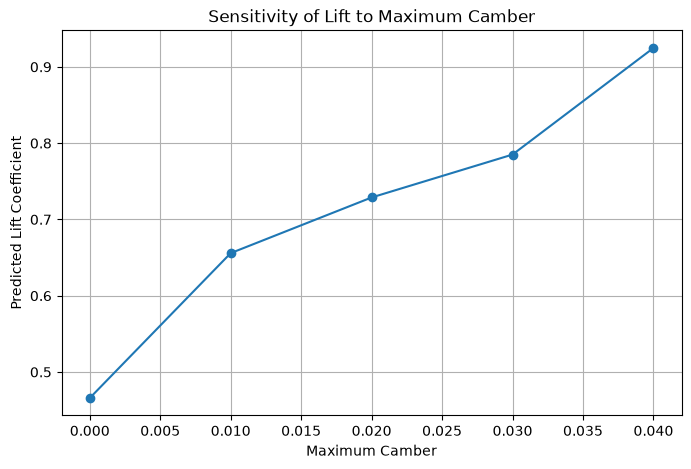

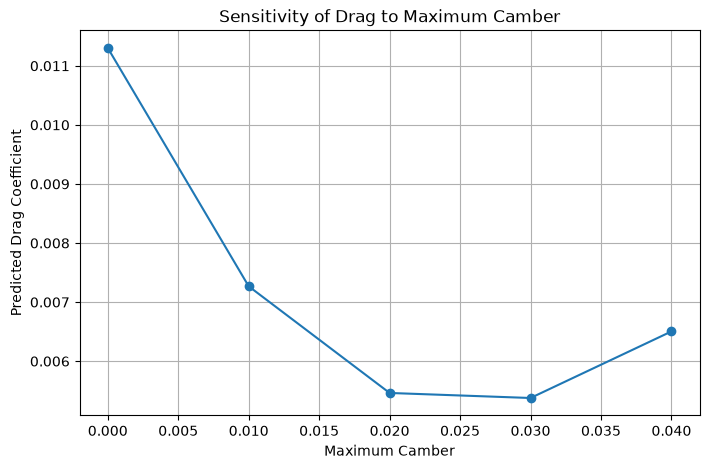

In [17]:
plt.figure(figsize=(8, 5))

plt.plot(
    camber_sensitivity["max_camber"],
    camber_sensitivity["CL_pred"],
    marker="o",
)

plt.xlabel("Maximum Camber")
plt.ylabel("Predicted Lift Coefficient")

plt.title(
    "Sensitivity of Lift to Maximum Camber"
)

plt.grid()
plt.show() 

plt.figure(figsize=(8, 5))

plt.plot(
    camber_sensitivity["max_camber"],
    camber_sensitivity["CD_pred"],
    marker="o",
)

plt.xlabel("Maximum Camber")
plt.ylabel("Predicted Drag Coefficient")

plt.title(
    "Sensitivity of Drag to Maximum Camber"
)

plt.grid()
plt.show()

In [18]:
thickness_values = np.array([
    0.09,
    0.105,
    0.12,
    0.135,
    0.15,
])

thickness_sensitivity = pd.DataFrame({
    "max_camber": 0.02,
    "camber_position": 0.4,
    "thickness": thickness_values,
    "reynolds": 300000,
    "alpha": 4.0,
})

thickness_sensitivity["CL_pred"] = (
    cl_model.predict(
        thickness_sensitivity[features]
    )
)

thickness_sensitivity["CD_pred"] = (
    cd_model.predict(
        thickness_sensitivity[features]
    )
)

thickness_sensitivity

,max_camber,camber_position,thickness,reynolds,alpha,CL_pred,CD_pred
0,0.02,0.4,0.090,300000,4.0,0.701392,0.006192
1,0.02,0.4,0.105,300000,4.0,0.719429,0.006032
2,0.02,0.4,0.120,300000,4.0,0.728801,0.005462
3,0.02,0.4,0.135,300000,4.0,0.732100,0.006058
4,0.02,0.4,0.150,300000,4.0,0.731916,0.009395


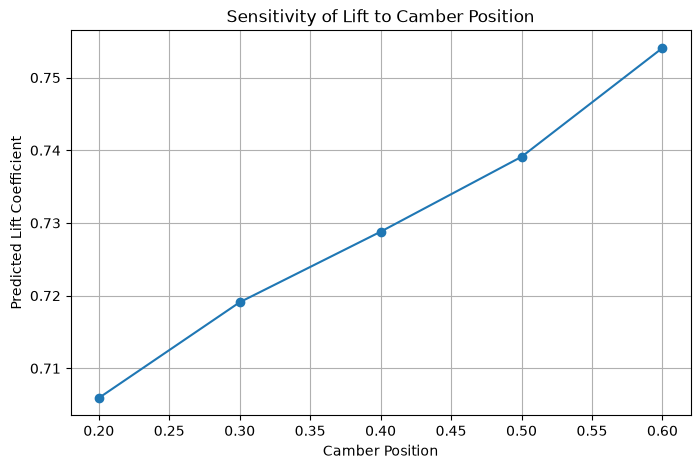

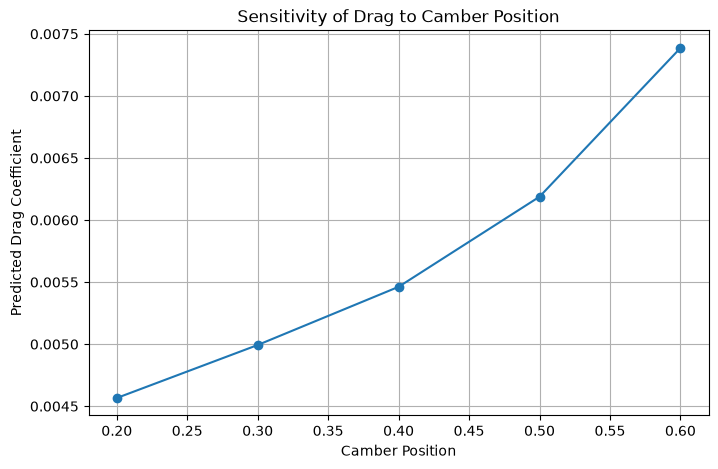

In [21]:
camber_sensitivity = pd.DataFrame({
    "max_camber": [
        0.00,
        0.01,
        0.02,
        0.03,
        0.04,
    ],

    "camber_position": [
        0.0,
        0.4,
        0.4,
        0.4,
        0.4,
    ],

    "thickness": 0.12,
    "reynolds": 300000,
    "alpha": 4.0,
})


camber_sensitivity["CL_pred"] = (
    cl_model.predict(
        camber_sensitivity[features]
    )
)

camber_sensitivity["CD_pred"] = (
    cd_model.predict(
        camber_sensitivity[features]
    )
)

camber_sensitivity

position_values = np.array([
    0.2,
    0.3,
    0.4,
    0.5,
    0.6,
])

position_sensitivity = pd.DataFrame({
    "max_camber": 0.02,
    "camber_position": position_values,
    "thickness": 0.12,
    "reynolds": 300000,
    "alpha": 4.0,
})


position_sensitivity["CL_pred"] = (
    cl_model.predict(
        position_sensitivity[features]
    )
)

position_sensitivity["CD_pred"] = (
    cd_model.predict(
        position_sensitivity[features]
    )
)

position_sensitivity 

plt.figure(figsize=(8, 5))

plt.plot(
    position_sensitivity["camber_position"],
    position_sensitivity["CL_pred"],
    marker="o",
)

plt.xlabel("Camber Position")
plt.ylabel("Predicted Lift Coefficient")
plt.title("Sensitivity of Lift to Camber Position")

plt.grid()
plt.show() 

plt.figure(figsize=(8, 5))

plt.plot(
    position_sensitivity["camber_position"],
    position_sensitivity["CD_pred"],
    marker="o",
)

plt.xlabel("Camber Position")
plt.ylabel("Predicted Drag Coefficient")
plt.title("Sensitivity of Drag to Camber Position")

plt.grid()
plt.show()